Phase 1 — Data Loading, RFM Engineering & EDA

In [3]:
# ==========================================
# 1. DATA LOADING & CLEANING
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Load Dataset
file_path = "ecommerce_customer_behavior_dataset_v2.csv"
df = pd.read_csv(file_path)
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

print("=== 1. DATASET OVERVIEW ===")
print("Dataset Shape:", df.shape)
print("Unique Customers:", df['Customer_ID'].nunique())
print("Unique Orders:", df['Order_ID'].nunique())
print("Date Range:", df['Date'].min().date(), "to", df['Date'].max().date())

# 2. Data Quality Check & Cleaning
print("\n=== 2. DATA CLEANING ===")
print("Missing Values in essential columns:")
print(df[['Customer_ID', 'Order_ID', 'Date', 'Total_Amount']].isnull().sum())

before_rows = len(df)
duplicates = df.duplicated().sum()
df = df.drop_duplicates().copy()

print(f"Duplicate rows found and removed: {duplicates}")
print(f"Cleaned Dataset Shape: {df.shape}")

=== 1. DATASET OVERVIEW ===
Dataset Shape: (17049, 18)
Unique Customers: 5000
Unique Orders: 17049
Date Range: 2023-01-01 to 2024-03-25

=== 2. DATA CLEANING ===
Missing Values in essential columns:
Customer_ID     0
Order_ID        0
Date            0
Total_Amount    0
dtype: int64
Duplicate rows found and removed: 0
Cleaned Dataset Shape: (17049, 18)


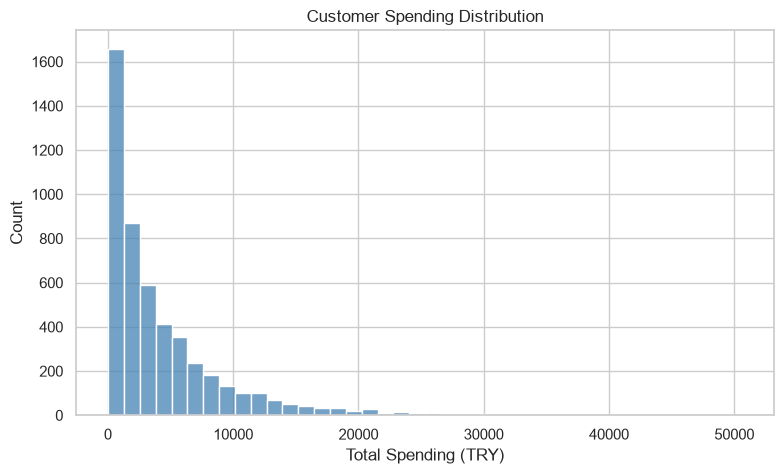

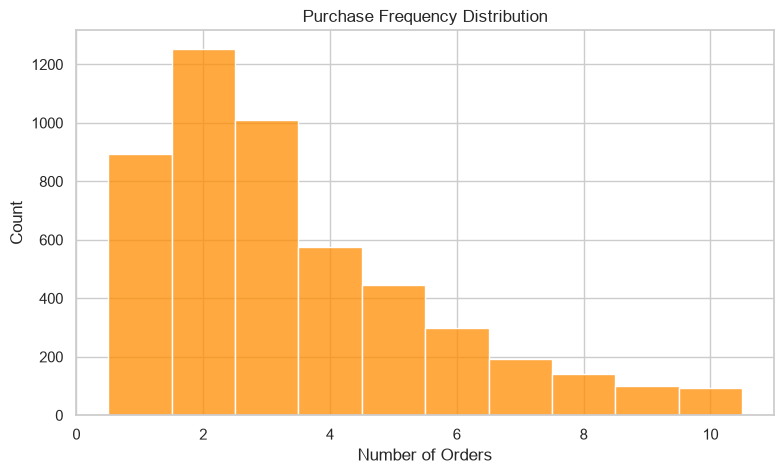

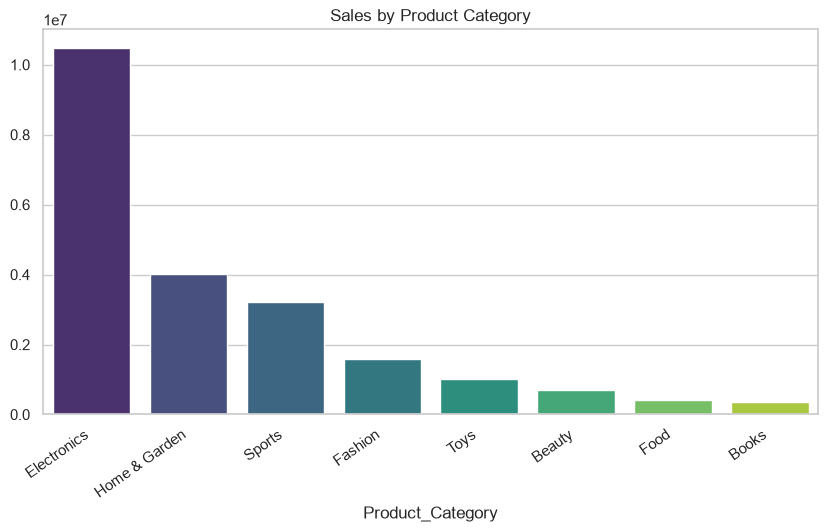

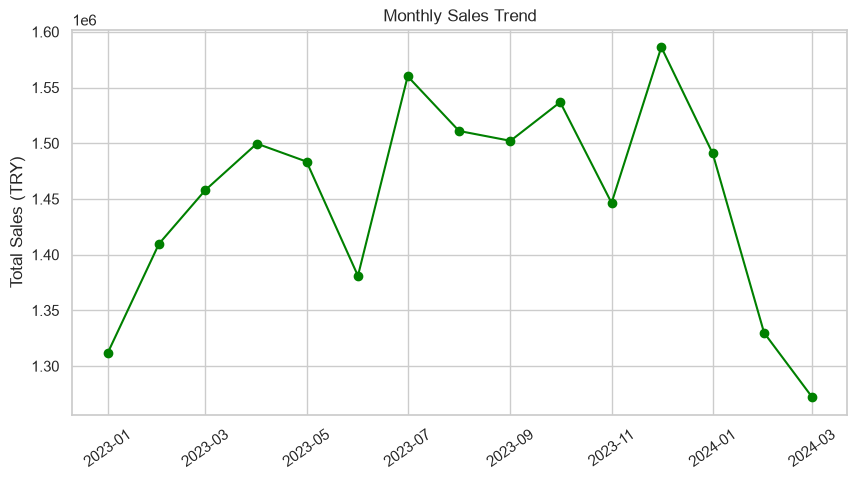

In [5]:
# ==========================================
# 2. EXPLORATORY DATA ANALYSIS
# ==========================================
# 1. Distribution of Total Customer Spending
customer_summary = df.groupby("Customer_ID").agg(
    Total_Spending=("Total_Amount", "sum"),
    Purchase_Frequency=("Order_ID", "nunique")
).reset_index()

plt.figure(figsize=(9, 5))
sns.histplot(customer_summary["Total_Spending"], bins=40, color="steelblue")
plt.title("Customer Spending Distribution")
plt.xlabel("Total Spending (TRY)")
plt.show()

# 2. Customer Purchase Frequency Distribution
plt.figure(figsize=(9, 5))
sns.histplot(customer_summary["Purchase_Frequency"], discrete=True, color="darkorange")
plt.title("Purchase Frequency Distribution")
plt.xlabel("Number of Orders")
plt.show()

# 3. Sales by Product Category
category_sales = df.groupby("Product_Category")["Total_Amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=category_sales.index, y=category_sales.values, hue=category_sales.index, palette="viridis", legend=False)
plt.title("Sales by Product Category")
plt.xticks(rotation=35, ha="right")
plt.show()

# 4. Monthly Sales Trend
monthly_sales = df.set_index("Date").resample("MS")["Total_Amount"].sum()
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", color="green")
plt.title("Monthly Sales Trend")
plt.ylabel("Total Sales (TRY)")
plt.xticks(rotation=35)
plt.show()

In [2]:

# ==========================================
# 3. RFM FEATURE ENGINEERING
# ==========================================

# Set reference date to one day after
# the latest transaction date

reference_date = df['Date'].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date.date())

# Group transactions by Customer_ID
rfm = df.groupby('Customer_ID').agg(
    
    # Most recent purchase date
    Last_Purchase_Date=('Date', 'max'),

    # Count distinct orders
    Frequency=('Order_ID', 'nunique'),

    # Total customer spending
    Monetary=('Total_Amount', 'sum')
)

# Calculate Recency in days
rfm['Recency'] = (
    reference_date - rfm['Last_Purchase_Date']
).dt.days

# Remove intermediate date column
rfm = rfm.drop(columns=['Last_Purchase_Date'])

# Arrange columns in RFM order
rfm = rfm[['Recency', 'Frequency', 'Monetary']]

# ==========================================
# 4. DISPLAY RFM RESULTS
# ==========================================

print("\nFirst 5 Customers:")
print(rfm.head())

print("\nRFM DataFrame Shape:")
print(rfm.shape)

print("\nRFM Statistical Summary:")
print(rfm.describe())


Reference Date: 2024-03-26

First 5 Customers:
             Recency  Frequency  Monetary
Customer_ID                              
CUST_00001       112          3   2199.63
CUST_00002       284          2    809.90
CUST_00003        83          2   3030.81
CUST_00004        42          1    383.22
CUST_00005       279          3   2422.73

RFM DataFrame Shape:
(5000, 3)

RFM Statistical Summary:
           Recency    Frequency      Monetary
count  5000.000000  5000.000000   5000.000000
mean    125.716400     3.409800   4355.810518
std     108.050972     2.181746   5274.546636
min       1.000000     1.000000     14.280000
25%      39.000000     2.000000    889.410000
50%      94.000000     3.000000   2493.925000
75%     185.000000     5.000000   5796.297500
max     450.000000    10.000000  50628.150000


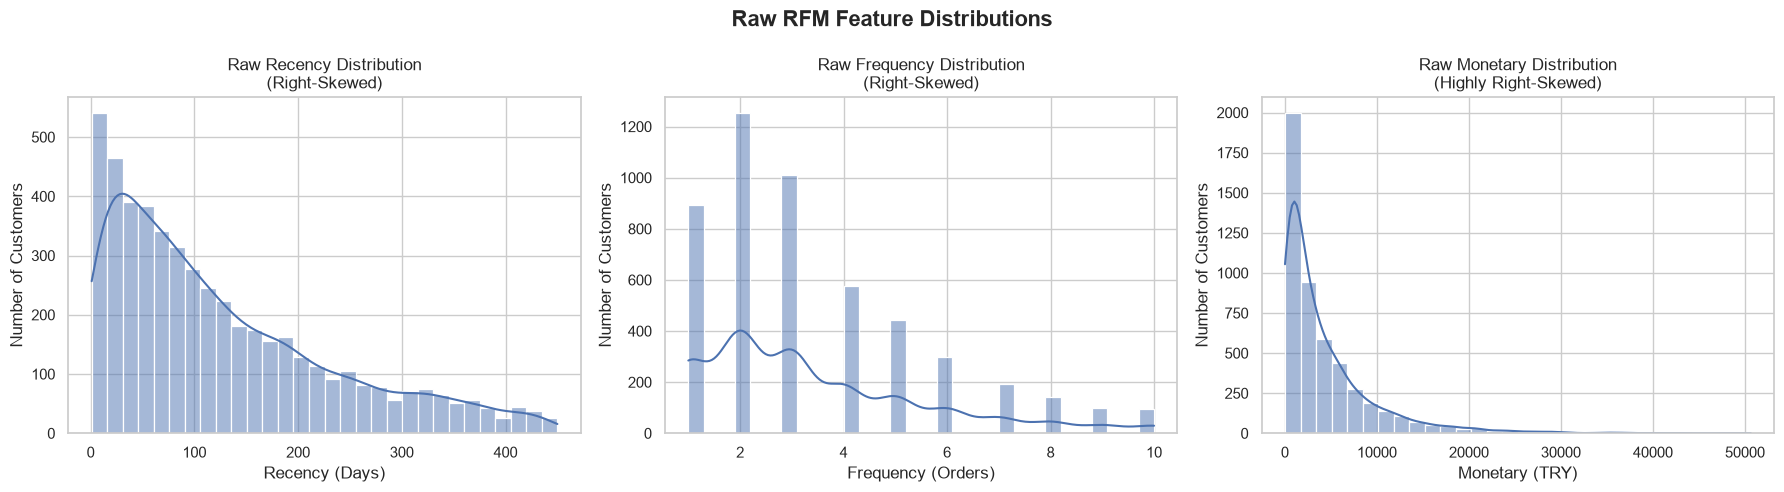


Raw RFM Skewness:
Recency      1.025482
Frequency    1.113005
Monetary     2.549442
dtype: float64


In [3]:

# ==========================================
# 5. RAW RFM DISTRIBUTIONS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency distribution
sns.histplot(
    rfm['Recency'],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title(
    'Raw Recency Distribution\n(Right-Skewed)'
)
axes[0].set_xlabel('Recency (Days)')
axes[0].set_ylabel('Number of Customers')

# Frequency distribution
sns.histplot(
    rfm['Frequency'],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title(
    'Raw Frequency Distribution\n(Right-Skewed)'
)
axes[1].set_xlabel('Frequency (Orders)')
axes[1].set_ylabel('Number of Customers')

# Monetary distribution
sns.histplot(
    rfm['Monetary'],
    bins=30,
    kde=True,
    ax=axes[2]
)
axes[2].set_title(
    'Raw Monetary Distribution\n(Highly Right-Skewed)'
)
axes[2].set_xlabel('Monetary (TRY)')
axes[2].set_ylabel('Number of Customers')

plt.suptitle(
    'Raw RFM Feature Distributions',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Calculate skewness numerically
print("\nRaw RFM Skewness:")
print(rfm.skew())


In [4]:

# ==========================================
# 6. LOG TRANSFORMATION
# ==========================================

rfm_log = np.log1p(rfm)

print("Log-transformed RFM:")
print(rfm_log.head())

# ==========================================
# 7. STANDARDIZATION
# ==========================================

scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log),
    columns=rfm_log.columns,
    index=rfm_log.index
)

print("\nScaled RFM DataFrame:")
print(rfm_scaled.head())

print("\nScaled DataFrame Shape:")
print(rfm_scaled.shape)

# Verify mean and standard deviation
print("\nFeature Means:")
print(rfm_scaled.mean())

print("\nFeature Standard Deviations:")
print(rfm_scaled.std())


Log-transformed RFM:
              Recency  Frequency  Monetary
Customer_ID                               
CUST_00001   4.727388   1.386294  7.696499
CUST_00002   5.652489   1.098612  6.698145
CUST_00003   4.430817   1.098612  8.016915
CUST_00004   3.761200   0.693147  5.951215
CUST_00005   5.634790   1.386294  7.793063

Scaled RFM DataFrame:
              Recency  Frequency  Monetary
Customer_ID                               
CUST_00001   0.323613   0.029862  0.030487
CUST_00002   1.134660  -0.585980 -0.703359
CUST_00003   0.063606  -0.585980  0.266011
CUST_00004  -0.523454  -1.453959 -1.252394
CUST_00005   1.119142   0.029862  0.101467

Scaled DataFrame Shape:
(5000, 3)

Feature Means:
Recency      9.379164e-17
Frequency    3.957723e-16
Monetary     3.467449e-16
dtype: float64

Feature Standard Deviations:
Recency      1.0001
Frequency    1.0001
Monetary     1.0001
dtype: float64


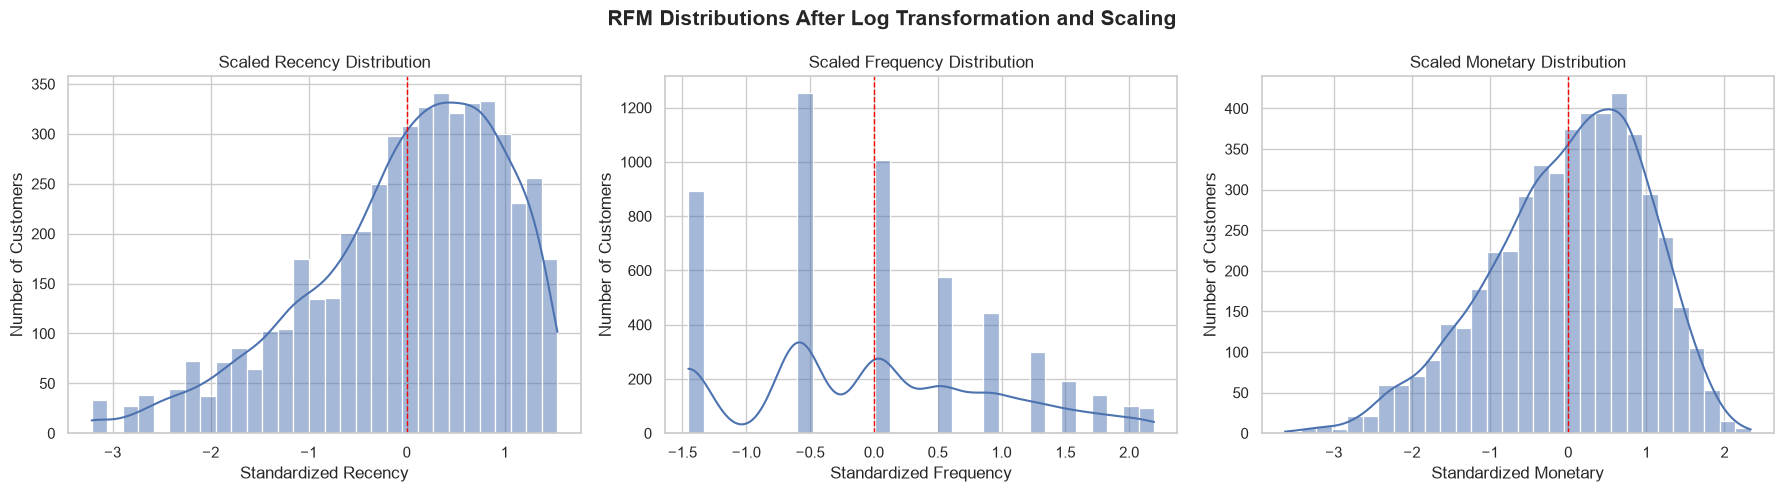

In [5]:

# ==========================================
# 8. TRANSFORMED RFM DISTRIBUTIONS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ['Recency', 'Frequency', 'Monetary']

for i, feature in enumerate(features):

    sns.histplot(
        rfm_scaled[feature],
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(
        f'Scaled {feature} Distribution'
    )

    axes[i].set_xlabel(
        f'Standardized {feature}'
    )

    axes[i].set_ylabel('Number of Customers')

    # Reference line at zero
    axes[i].axvline(
        0,
        color='red',
        linestyle='--',
        linewidth=1
    )

plt.suptitle(
    'RFM Distributions After Log Transformation and Scaling',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


Phase 2: Optimal K Selection and K-Means Clustering

In [6]:

# ==========================================
# PHASE 2: OPTIMAL K SELECTION
# ==========================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Store evaluation results
inertia_values = []
silhouette_values = []

# Test K from 2 to 10
K_range = range(2, 11)

for k in K_range:

    # Initialize K-Means
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit model
    cluster_labels = kmeans.fit_predict(rfm_scaled)

    # Calculate Inertia (WCSS)
    inertia = kmeans.inertia_

    # Calculate Silhouette Score
    silhouette = silhouette_score(
        rfm_scaled,
        cluster_labels
    )

    # Store results
    inertia_values.append(inertia)
    silhouette_values.append(silhouette)

    print(
        f"K = {k} | "
        f"Inertia = {inertia:.2f} | "
        f"Silhouette Score = {silhouette:.4f}"
    )

K = 2 | Inertia = 8505.23 | Silhouette Score = 0.3605
K = 3 | Inertia = 6523.28 | Silhouette Score = 0.2931
K = 4 | Inertia = 5294.35 | Silhouette Score = 0.3068
K = 5 | Inertia = 4472.18 | Silhouette Score = 0.2908
K = 6 | Inertia = 4000.18 | Silhouette Score = 0.2626
K = 7 | Inertia = 3629.93 | Silhouette Score = 0.2584
K = 8 | Inertia = 3328.45 | Silhouette Score = 0.2660
K = 9 | Inertia = 3087.86 | Silhouette Score = 0.2620
K = 10 | Inertia = 2887.12 | Silhouette Score = 0.2501


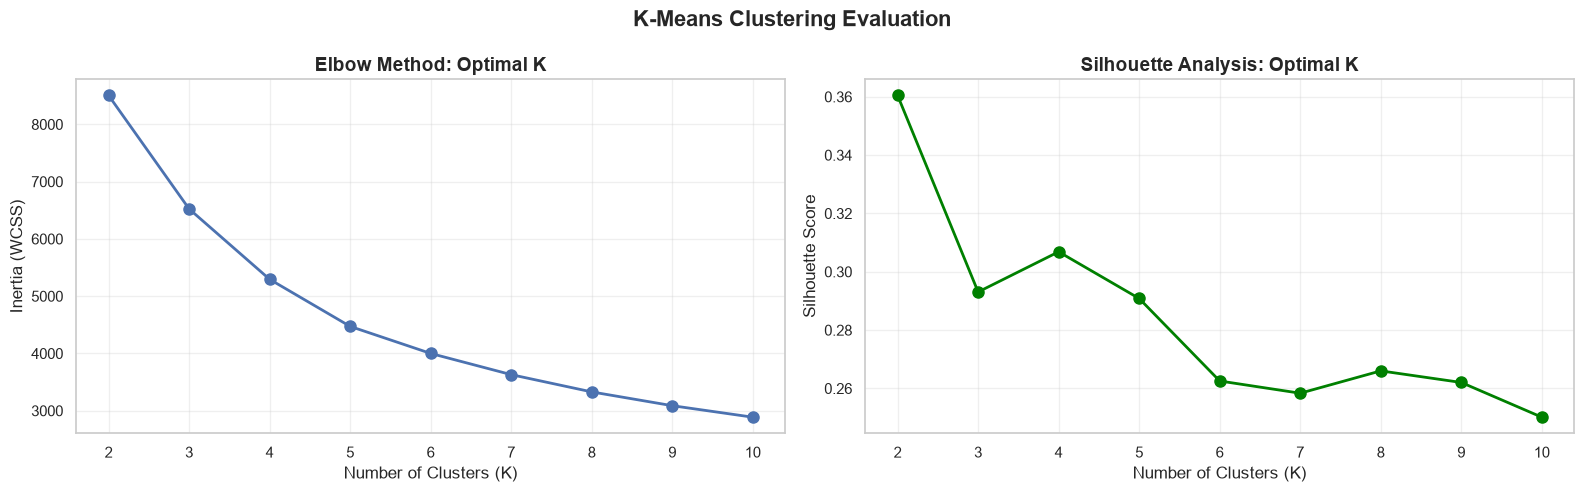


Clustering Evaluation Results:
 K   Inertia  Silhouette Score
 2 8505.2313            0.3605
 3 6523.2821            0.2931
 4 5294.3533            0.3068
 5 4472.1824            0.2908
 6 4000.1780            0.2626
 7 3629.9272            0.2584
 8 3328.4547            0.2660
 9 3087.8556            0.2620
10 2887.1181            0.2501


In [7]:

# ==========================================
# 2. ELBOW METHOD & SILHOUETTE ANALYSIS
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ------------------------------------------
# LEFT: ELBOW METHOD
# ------------------------------------------

axes[0].plot(
    list(K_range),
    inertia_values,
    marker='o',
    linestyle='-',
    linewidth=2,
    markersize=8
)

axes[0].set_title(
    'Elbow Method: Optimal K',
    fontsize=14,
    fontweight='bold'
)

axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_xticks(list(K_range))
axes[0].grid(True, alpha=0.3)

# ------------------------------------------
# RIGHT: SILHOUETTE SCORE
# ------------------------------------------

axes[1].plot(
    list(K_range),
    silhouette_values,
    marker='o',
    linestyle='-',
    linewidth=2,
    markersize=8,
    color='green'
)

axes[1].set_title(
    'Silhouette Analysis: Optimal K',
    fontsize=14,
    fontweight='bold'
)

axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(K_range))
axes[1].grid(True, alpha=0.3)

plt.suptitle(
    'K-Means Clustering Evaluation',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# ------------------------------------------
# DISPLAY RESULTS IN A TABLE
# ------------------------------------------

evaluation_results = pd.DataFrame({
    'K': list(K_range),
    'Inertia': inertia_values,
    'Silhouette Score': silhouette_values
})

print("\nClustering Evaluation Results:")
print(evaluation_results.round(4).to_string(index=False))


In [8]:

# ==========================================
# 3. FINAL K-MEANS CLUSTERING
# ==========================================

# Select optimal K based on evaluation results
optimal_k = 4

# Initialize final K-Means model
final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Fit and predict cluster labels
cluster_labels = final_kmeans.fit_predict(rfm_scaled)

# Assign cluster labels to original RFM DataFrame
rfm['Cluster'] = cluster_labels

# ==========================================
# DISPLAY CLUSTER RESULTS
# ==========================================

print("\nFinal K-Means Model")
print("-" * 40)

print("Optimal Number of Clusters:", optimal_k)

print("\nFirst 10 Customers with Cluster Labels:")
print(rfm.head(10))

# Count customers in each cluster
print("\nNumber of Customers per Cluster:")
print(rfm['Cluster'].value_counts().sort_index())

# Cluster proportions
print("\nCluster Distribution (%):")
print(
    (rfm['Cluster'].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)



Final K-Means Model
----------------------------------------
Optimal Number of Clusters: 4

First 10 Customers with Cluster Labels:
             Recency  Frequency  Monetary  Cluster
Customer_ID                                       
CUST_00001       112          3   2199.63        2
CUST_00002       284          2    809.90        1
CUST_00003        83          2   3030.81        2
CUST_00004        42          1    383.22        1
CUST_00005       279          3   2422.73        2
CUST_00006       212          3   1245.83        2
CUST_00007        81          1   1331.55        1
CUST_00008       169          3   5602.29        2
CUST_00009        39          1    470.86        1
CUST_00010        22          3   1421.16        3

Number of Customers per Cluster:
Cluster
0    1152
1    1293
2    1826
3     729
Name: count, dtype: int64

Cluster Distribution (%):
Cluster
0    23.04
1    25.86
2    36.52
3    14.58
Name: proportion, dtype: float64


PCA Explained Variance:
PC1: 65.20%
PC2: 24.27%
Total Explained Variance: 89.47%


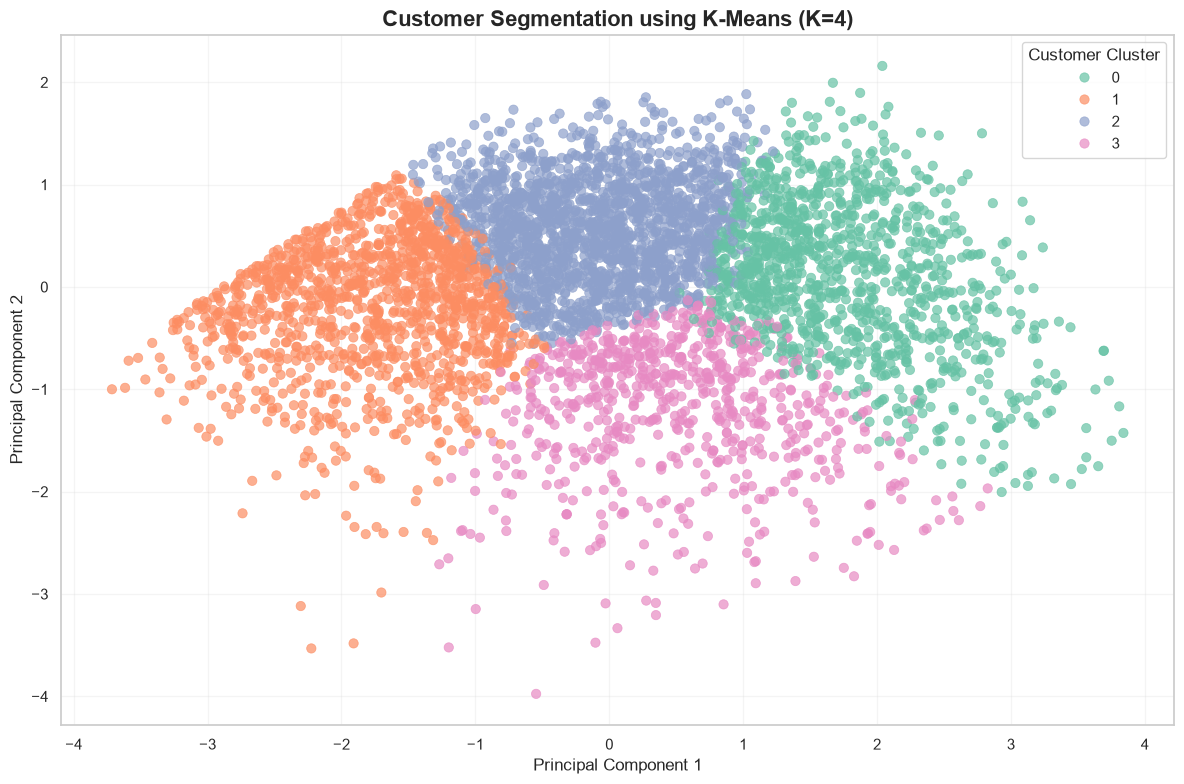

In [9]:

# ==========================================
# 4. PCA DIMENSIONALITY REDUCTION
# ==========================================

from sklearn.decomposition import PCA

# Initialize PCA with two components
pca = PCA(n_components=2)

# Transform scaled RFM features
rfm_pca = pca.fit_transform(rfm_scaled)

# Create PCA DataFrame
pca_df = pd.DataFrame(
    rfm_pca,
    columns=['PC1', 'PC2'],
    index=rfm.index
)

# Add cluster labels
pca_df['Cluster'] = rfm['Cluster']

# Explained variance
explained_variance = pca.explained_variance_ratio_

print("PCA Explained Variance:")
print(f"PC1: {explained_variance[0]*100:.2f}%")
print(f"PC2: {explained_variance[1]*100:.2f}%")

print(
    f"Total Explained Variance: "
    f"{sum(explained_variance)*100:.2f}%"
)

# ==========================================
# 5. PCA CLUSTER VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set2',
    s=45,
    alpha=0.7,
    edgecolor=None
)

plt.title(
    f'Customer Segmentation using K-Means (K={optimal_k})',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(
    title='Customer Cluster',
    loc='best'
)

plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()


Phase 3 - Cluster Profiling, Hierarchical Validation, and Business Interpretation

In [10]:

# ==========================================
# PHASE 3: CLUSTER PROFILING
# ==========================================

# Calculate mean RFM values for each cluster
cluster_profile = rfm.groupby('Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean()

# Round values for readability
cluster_profile = cluster_profile.round(2)

print("CUSTOMER CLUSTER PROFILES")
print("=" * 60)
print(cluster_profile)

# Display number of customers per cluster
cluster_sizes = rfm.groupby('Cluster').size()

print("\nCUSTOMER COUNT PER CLUSTER")
print("=" * 60)
print(cluster_sizes)

# Combine customer counts with RFM profiles
cluster_summary = cluster_profile.copy()
cluster_summary['Customer_Count'] = cluster_sizes
cluster_summary['Customer_Percentage'] = (
    cluster_sizes / len(rfm) * 100
).round(2)

print("\nCOMPLETE CLUSTER SUMMARY")
print("=" * 60)
print(cluster_summary)

CUSTOMER CLUSTER PROFILES
         Recency  Frequency  Monetary
Cluster                              
0          47.91       6.55   9661.07
1         210.71       1.47    576.93
2         156.29       2.99   4408.74
3          21.34       2.96   2542.08

CUSTOMER COUNT PER CLUSTER
Cluster
0    1152
1    1293
2    1826
3     729
dtype: int64

COMPLETE CLUSTER SUMMARY
         Recency  Frequency  Monetary  Customer_Count  Customer_Percentage
Cluster                                                                   
0          47.91       6.55   9661.07            1152                23.04
1         210.71       1.47    576.93            1293                25.86
2         156.29       2.99   4408.74            1826                36.52
3          21.34       2.96   2542.08             729                14.58


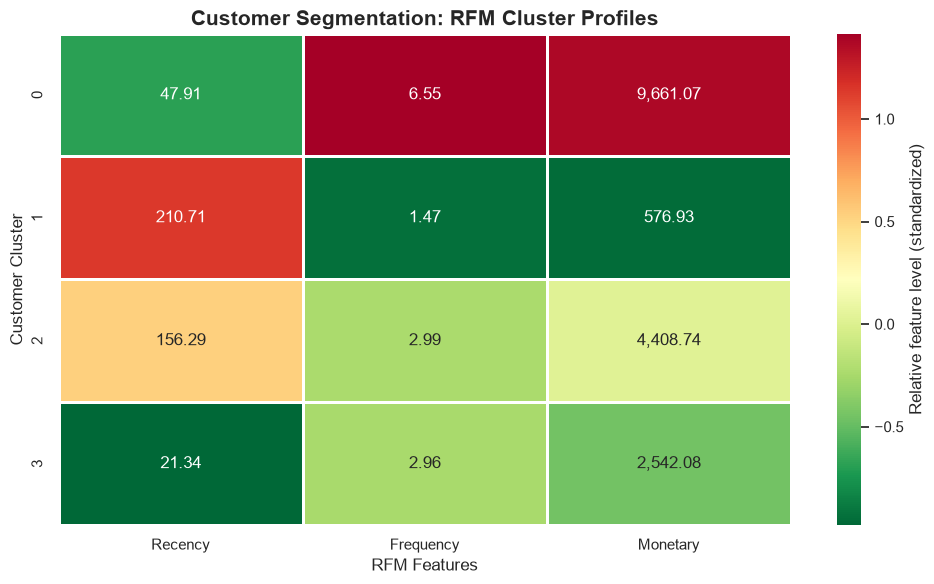

In [11]:

# ==========================================
# 1.2 RFM CLUSTER HEATMAP
# ==========================================

plt.figure(figsize=(10, 6))

# Normalize each feature for heatmap coloring
heatmap_colors = (
    cluster_profile - cluster_profile.mean()
) / cluster_profile.std()

# Keep original values as annotations
annotations = cluster_profile.map(lambda x: f'{x:,.2f}')

sns.heatmap(
    heatmap_colors,
    annot=annotations,
    fmt='',
    cmap='RdYlGn_r',
    linewidths=1,
    linecolor='white',
    cbar_kws={
        'label': 'Relative feature level (standardized)'
    }
)

plt.title(
    'Customer Segmentation: RFM Cluster Profiles',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('RFM Features')
plt.ylabel('Customer Cluster')

plt.tight_layout()
plt.show()


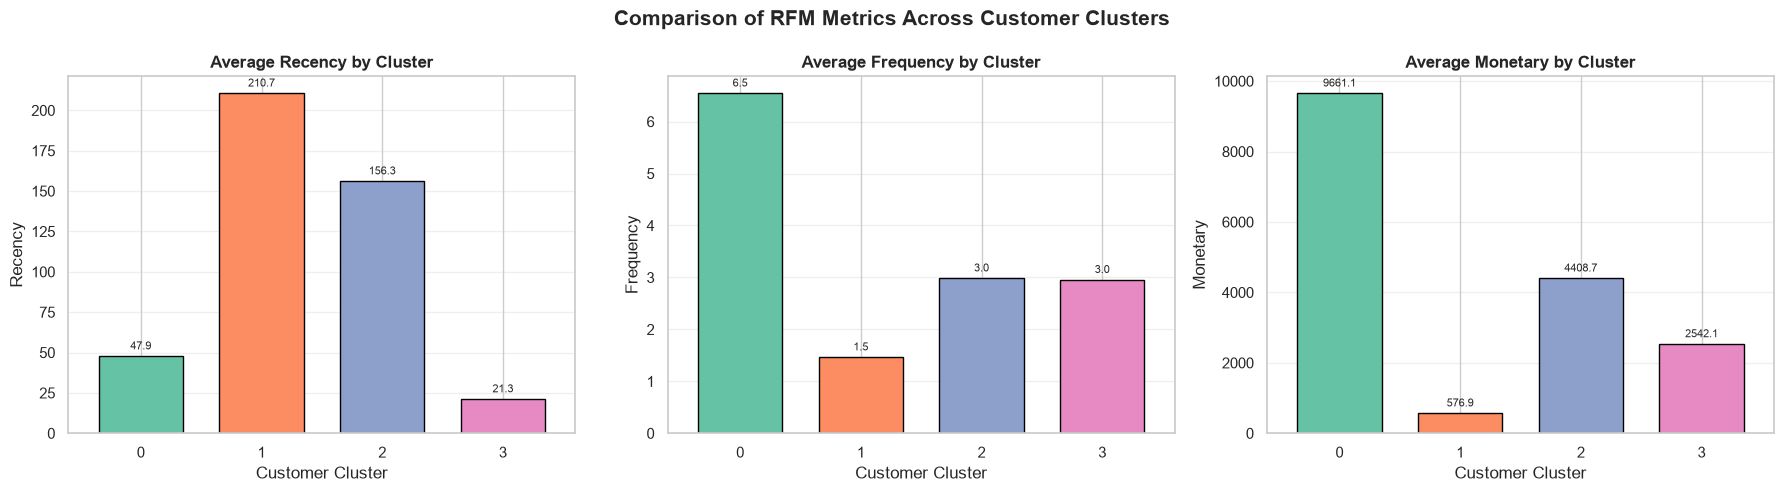

In [12]:

# ==========================================
# 1.3 RFM CLUSTER COMPARISON BAR CHARTS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ['Recency', 'Frequency', 'Monetary']

titles = [
    'Average Recency by Cluster',
    'Average Frequency by Cluster',
    'Average Monetary by Cluster'
]

colors = sns.color_palette('Set2', n_colors=4)

for i, feature in enumerate(features):

    cluster_profile[feature].plot(
        kind='bar',
        ax=axes[i],
        color=colors,
        edgecolor='black',
        width=0.7
    )

    axes[i].set_title(
        titles[i],
        fontsize=12,
        fontweight='bold'
    )

    axes[i].set_xlabel('Customer Cluster')
    axes[i].set_ylabel(feature)

    axes[i].tick_params(axis='x', rotation=0)
    axes[i].grid(axis='y', alpha=0.3)

    # Add numerical labels
    for container in axes[i].containers:
        axes[i].bar_label(
            container,
            fmt='%.1f',
            padding=3,
            fontsize=8
        )

plt.suptitle(
    'Comparison of RFM Metrics Across Customer Clusters',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


In [13]:

# ==========================================
# 2.1 IDENTIFY CLUSTER CHARACTERISTICS
# ==========================================

print("\nMOST RECENTLY ACTIVE CLUSTER:")
print(cluster_profile['Recency'].idxmin())

print("\nLEAST RECENTLY ACTIVE CLUSTER:")
print(cluster_profile['Recency'].idxmax())

print("\nHIGHEST FREQUENCY CLUSTER:")
print(cluster_profile['Frequency'].idxmax())

print("\nLOWEST FREQUENCY CLUSTER:")
print(cluster_profile['Frequency'].idxmin())

print("\nHIGHEST SPENDING CLUSTER:")
print(cluster_profile['Monetary'].idxmax())

print("\nLOWEST SPENDING CLUSTER:")
print(cluster_profile['Monetary'].idxmin())



MOST RECENTLY ACTIVE CLUSTER:
3

LEAST RECENTLY ACTIVE CLUSTER:
1

HIGHEST FREQUENCY CLUSTER:
0

LOWEST FREQUENCY CLUSTER:
1

HIGHEST SPENDING CLUSTER:
0

LOWEST SPENDING CLUSTER:
1


In [30]:

# ==========================================
# 2.2 BUSINESS SEGMENT NAMING
# ==========================================

# Replace the example names after examining
# your actual cluster_profile table.

cluster_names = {
    0: 'Champions',
    1: 'Hibernating Customers',
    2: 'High-Value At-Risk Customers',
    3: 'Active Promising'
}

# Add descriptive names to the original RFM DataFrame
rfm['Segment'] = rfm['Cluster'].map(cluster_names)

# Display customer counts by business segment
print("\nCUSTOMER SEGMENT DISTRIBUTION")

print(
    rfm.groupby('Segment').size()
    .sort_values(ascending=False)
)

# Display final segment profiles
business_profile = rfm.groupby('Segment')[
    ['Recency', 'Frequency', 'Monetary']
].mean().round(2)

print("\nBUSINESS SEGMENT PROFILES")
print(business_profile)



CUSTOMER SEGMENT DISTRIBUTION
Segment
High-Value At-Risk Customers    1826
Hibernating Customers           1293
Champions                       1152
Active Promising                 729
dtype: int64

BUSINESS SEGMENT PROFILES
                              Recency  Frequency  Monetary
Segment                                                   
Active Promising                21.34       2.96   2542.08
Champions                       47.91       6.55   9661.07
Hibernating Customers          210.71       1.47    576.93
High-Value At-Risk Customers   156.29       2.99   4408.74


In [31]:

# ==========================================
# 3. HIERARCHICAL CLUSTERING
# ==========================================

from sklearn.cluster import AgglomerativeClustering

# Initialize Agglomerative Clustering
hierarchical_model = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

# Fit the model and generate labels
hierarchical_labels = hierarchical_model.fit_predict(
    rfm_scaled
)

# Store hierarchical labels
rfm['Hierarchical_Cluster'] = hierarchical_labels

# Display cluster distribution
print("\nHIERARCHICAL CLUSTER DISTRIBUTION")
print("=" * 50)

print(
    rfm['Hierarchical_Cluster']
    .value_counts()
    .sort_index()
)

print("\nFirst 10 customer assignments:")
print(
    rfm[
        ['Cluster', 'Hierarchical_Cluster']
    ].head(10)
)



HIERARCHICAL CLUSTER DISTRIBUTION
Hierarchical_Cluster
0    1997
1    1043
2    1288
3     672
Name: count, dtype: int64

First 10 customer assignments:
             Cluster  Hierarchical_Cluster
Customer_ID                               
CUST_00001         2                     0
CUST_00002         1                     2
CUST_00003         2                     3
CUST_00004         1                     2
CUST_00005         2                     0
CUST_00006         2                     0
CUST_00007         1                     0
CUST_00008         2                     0
CUST_00009         1                     2
CUST_00010         3                     3


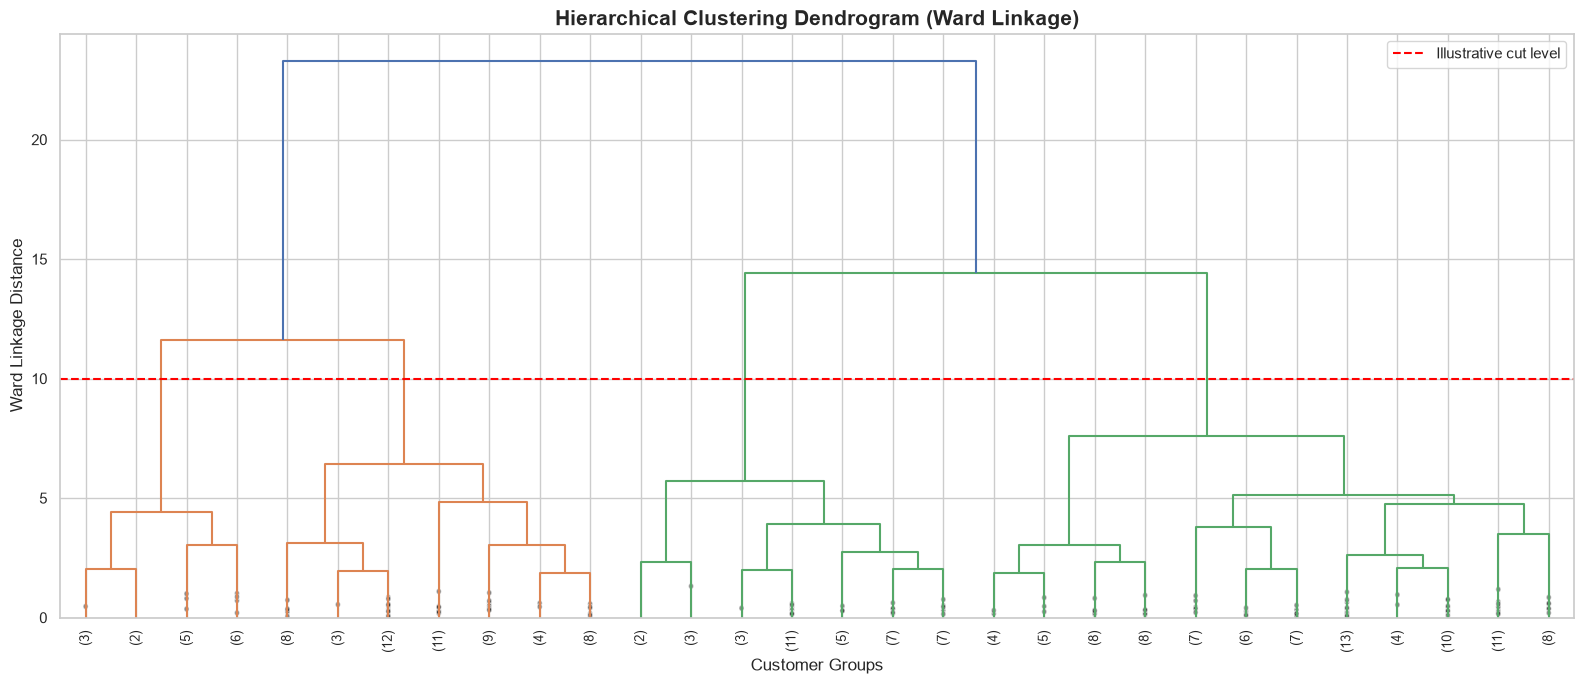

In [32]:

# ==========================================
# 3.2 HIERARCHICAL DENDROGRAM
# ==========================================

from scipy.cluster.hierarchy import dendrogram, linkage

# Select a random sample of 200 customers
sample_size = 200

rfm_sample = rfm_scaled.sample(
    n=sample_size,
    random_state=42
)

# Calculate hierarchical linkage
Z = linkage(
    rfm_sample,
    method='ward',
    metric='euclidean'
)

# Plot dendrogram
plt.figure(figsize=(16, 7))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)

plt.title(
    'Hierarchical Clustering Dendrogram (Ward Linkage)',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Customer Groups')
plt.ylabel('Ward Linkage Distance')

plt.axhline(
    y=10,
    color='red',
    linestyle='--',
    label='Illustrative cut level'
)

plt.legend()
plt.tight_layout()
plt.show()


In [33]:

# ==========================================
# 3.3 CLUSTERING AGREEMENT METRICS
# ==========================================

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Compare K-Means and Hierarchical assignments
ari = adjusted_rand_score(
    rfm['Cluster'],
    rfm['Hierarchical_Cluster']
)

nmi = normalized_mutual_info_score(
    rfm['Cluster'],
    rfm['Hierarchical_Cluster']
)

print("\nCLUSTERING VALIDATION RESULTS")
print("=" * 50)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")



CLUSTERING VALIDATION RESULTS
Adjusted Rand Index (ARI): 0.6101
Normalized Mutual Information (NMI): 0.5756


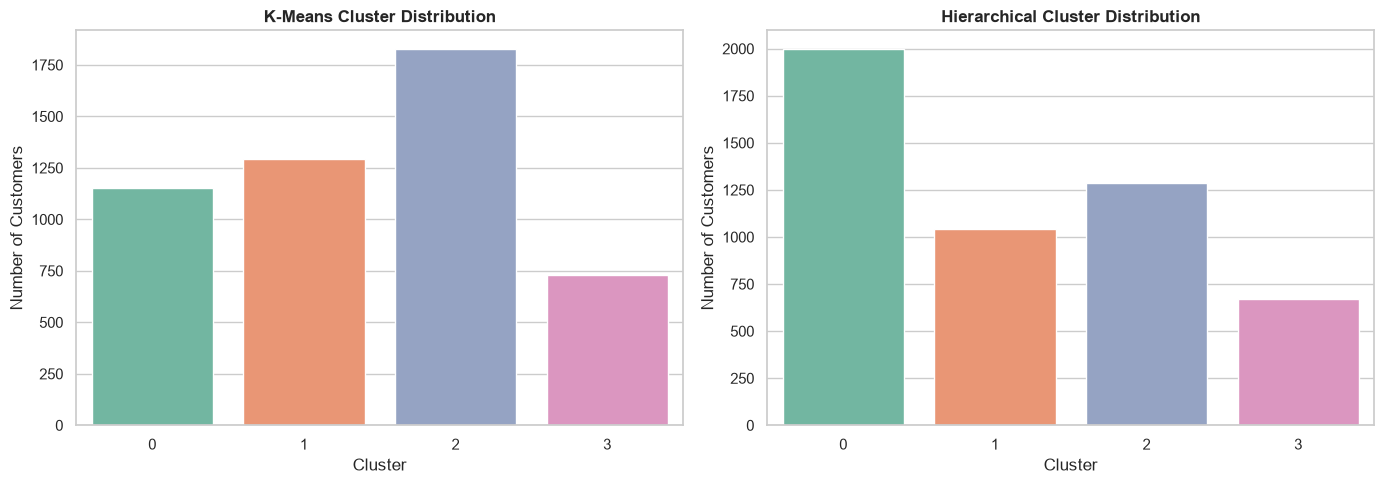

In [34]:

# ==========================================
# 3.4 COMPARE CLUSTER DISTRIBUTIONS
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-Means distribution
sns.countplot(
    data=rfm,
    x='Cluster',
    hue='Cluster',
    palette='Set2',
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    'K-Means Cluster Distribution',
    fontweight='bold'
)

axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Number of Customers')

# Hierarchical distribution
sns.countplot(
    data=rfm,
    x='Hierarchical_Cluster',
    hue='Hierarchical_Cluster',
    palette='Set2',
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    'Hierarchical Cluster Distribution',
    fontweight='bold'
)

axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()
